# BM25F — Expert failure analysis

Diagnostics for **known-positive expert instances**, comparing standard and discounted CombSUM across document retrieval depths. These are not exhaustive relevance judgments.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Works when this notebook lives in testing/, and also when opened elsewhere.
DATA_DIR = Path.cwd()
if not (DATA_DIR / "bm25_failure_analysis" / "expert_failure_details.csv").exists():
    DATA_DIR = Path.cwd() / "testing"
OUTPUT = DATA_DIR / "bm25_failure_analysis"
DETAILS = OUTPUT / "expert_failure_details.csv"
SUMMARY = OUTPUT / "failure_summary.csv"
if not DETAILS.exists():
    # Alternatively place the two CSV files beside this notebook.
    OUTPUT = DATA_DIR
    DETAILS = OUTPUT / "expert_failure_details.csv"
    SUMMARY = OUTPUT / "failure_summary.csv"
assert DETAILS.exists() and SUMMARY.exists(), f"Files not found in {OUTPUT}"

df = pd.read_csv(DETAILS)
summary = pd.read_csv(SUMMARY)
DEPTHS = sorted(summary['depth'].unique())
METHODS = ['combsum', 'discounted']
PLOT_DIR = OUTPUT / 'notebook_plots'
PLOT_DIR.mkdir(parents=True, exist_ok=True)
print(f"{len(df)} expected-expert instances, {df.query_id.nunique()} query IDs; depths {DEPTHS}")
display(df.head(3))

586 expected-expert instances, 452 query IDs; depths [np.int64(100), np.int64(250), np.int64(500)]


,query_id,query,query_type,expected_expert,matched_researcher_uuids,indexed_document_count,retrieved_document_count_100,expert_document_hits_100,rank_combsum_100,status_at_100_combsum,...,rank_combsum_250,status_at_250_combsum,rank_discounted_250,status_at_250_discounted,retrieved_document_count_500,expert_document_hits_500,rank_combsum_500,status_at_500_combsum,rank_discounted_500,status_at_500_discounted
0,1,digital biomarkers for mental health,academic,Stella Grasshof,ad50bed7-77fd-4c7f-819c-54455506e3f0,31,100,0,NaN,no_document_in_top_100,...,92.0,ranking_failure,92.0,ranking_failure,500,1,119.0,ranking_failure,119.0,ranking_failure
1,1,digital biomarkers for mental health,academic,Martin Lund Trinhammer,0600e907-f51e-4588-923c-9a984592580e,1,100,0,NaN,no_document_in_top_100,...,NaN,no_document_retrieved,NaN,no_document_retrieved,500,0,NaN,no_document_retrieved,NaN,no_document_retrieved
2,2,Can AI use facial expressions to help understa...,student_style,Stella Grasshof,ad50bed7-77fd-4c7f-819c-54455506e3f0,31,100,4,6.0,in_top_10,...,7.0,in_top_10,6.0,in_top_10,500,8,12.0,ranking_failure,7.0,in_top_10


## 1. Failure types by query category (depth 100)

Each bar represents expected-expert instances. **No document retrieved** means the expert has no associated document among the top 100; it does not prove the expert is absent from the index.

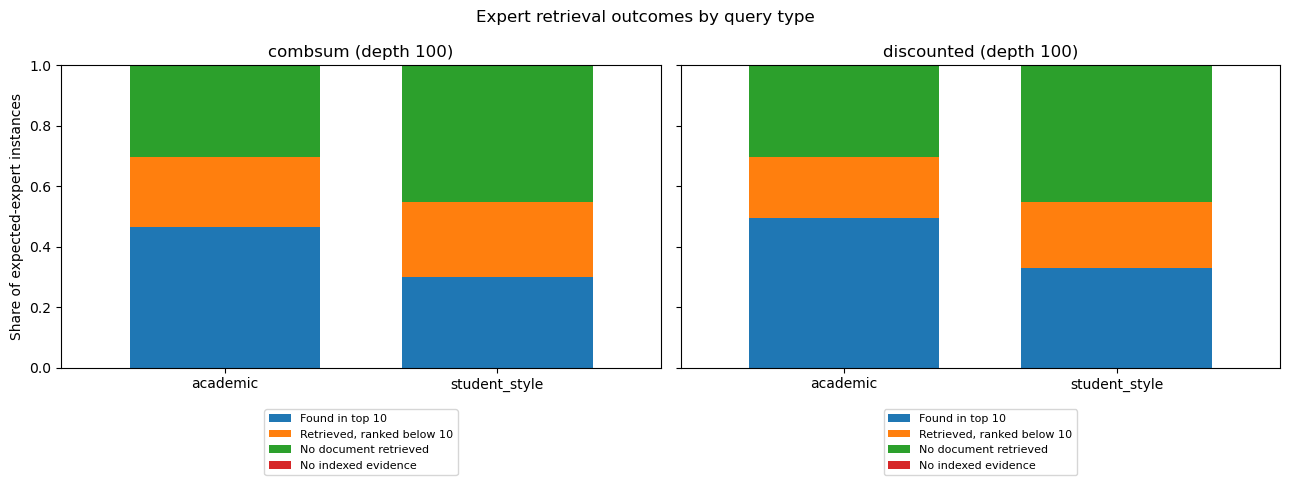

In [2]:
depth = 100
status_labels = {'in_top_10':'Found in top 10', 'ranking_failure':'Retrieved, ranked below 10',
                 'no_document_in_top_100':'No document retrieved',
                 'no_document_retrieved':'No document retrieved', 'not_in_index':'No indexed evidence'}
order = ['Found in top 10', 'Retrieved, ranked below 10', 'No document retrieved', 'No indexed evidence']
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, method in zip(axes, METHODS):
    col = f'status_at_{depth}_{method}'
    temp = df.assign(status=df[col].map(status_labels).fillna(df[col]))
    tab = pd.crosstab(temp.query_type, temp.status, normalize='index').reindex(columns=order, fill_value=0)
    tab.plot(kind='bar', stacked=True, ax=ax, width=.7)
    ax.set(title=f'{method} (depth {depth})', xlabel='', ylabel='Share of expected-expert instances')
    ax.set_ylim(0, 1)
    ax.tick_params(axis='x', rotation=0)
    ax.legend(loc='upper center', bbox_to_anchor=(.5, -0.12), fontsize=8)
fig.suptitle('Expert retrieval outcomes by query type')
fig.tight_layout()
fig.savefig(PLOT_DIR / '01_failure_types_by_query_type.png', dpi=180, bbox_inches='tight')
plt.show()

## 2. Known-positive top-10 coverage vs. retrieval depth

A higher retrieval depth increases the pool of documents, but may also increase competing researchers’ aggregate scores.

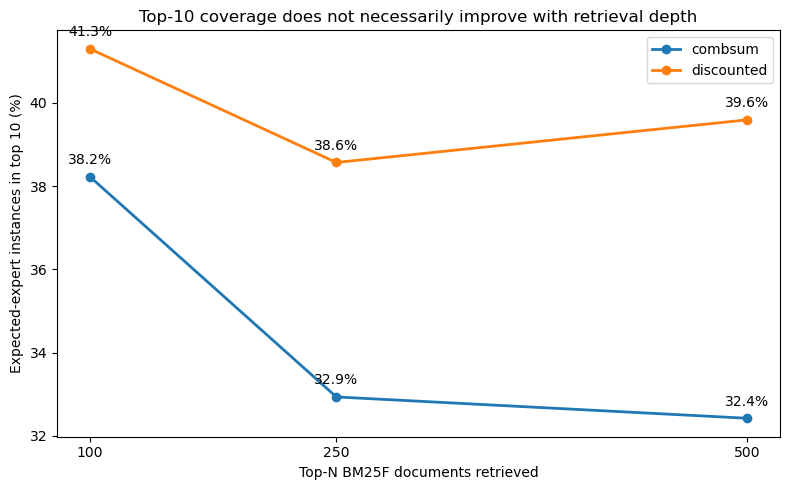

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
for method in METHODS:
    s = summary[(summary.query_type == 'ALL') & (summary.method == method) & (summary.status == 'in_top_10')].sort_values('depth')
    ax.plot(s.depth, s.fraction * 100, marker='o', linewidth=2, label=method)
    for _, r in s.iterrows():
        ax.annotate(f"{r['fraction']*100:.1f}%", (r.depth, r.fraction*100), xytext=(0, 9), textcoords='offset points', ha='center')
ax.set(xlabel='Top-N BM25F documents retrieved', ylabel='Expected-expert instances in top 10 (%)',
       title='Top-10 coverage does not necessarily improve with retrieval depth')
ax.set_xticks(DEPTHS)
ax.legend()
fig.tight_layout()
fig.savefig(PLOT_DIR / '02_top10_coverage_by_depth.png', dpi=180)
plt.show()

## 3. Where are missing experts lost?

The chart shows the share of instances with no retrieved documents, with retrieved documents but a rank below 10, and successfully ranked in the top 10. Here we use **Discounted CombSUM**.

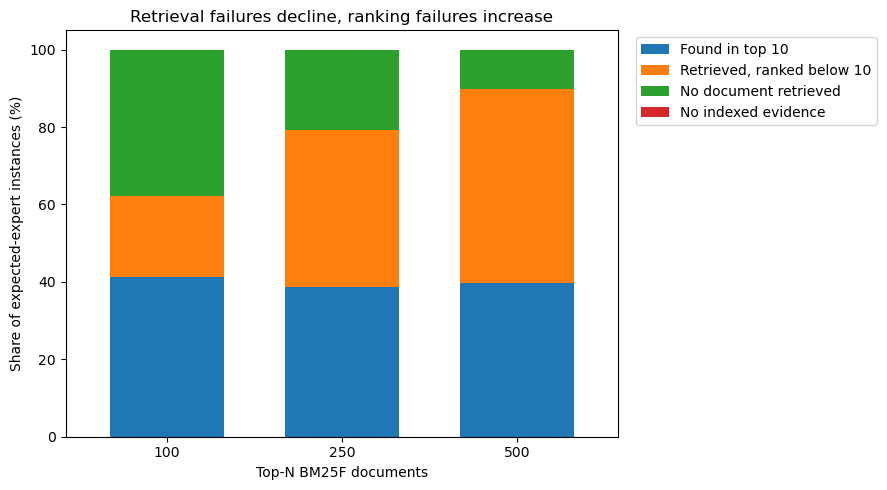

status  Found in top 10  Retrieved, ranked below 10  No document retrieved  \
depth                                                                        
100                 242                         122                    222   
250                 226                         239                    121   
500                 232                         295                     59   

status  No indexed evidence  
depth                        
100                       0  
250                       0  
500                       0  


In [4]:
method = 'discounted'
records=[]
for depth in DEPTHS:
    s = df[f'status_at_{depth}_{method}'].map(status_labels)
    for label in order:
        records.append({'depth':depth, 'status':label, 'count':(s == label).sum()})
plot_df = pd.DataFrame(records).pivot(index='depth', columns='status', values='count').reindex(columns=order, fill_value=0)
ax = (plot_df / len(df) * 100).plot(kind='bar', stacked=True, figsize=(9, 5), width=.65)
ax.set(xlabel='Top-N BM25F documents', ylabel='Share of expected-expert instances (%)',
       title='Retrieval failures decline, ranking failures increase')
ax.tick_params(axis='x', rotation=0)
ax.legend(title='', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig(PLOT_DIR / '03_failure_composition_by_depth.png', dpi=180, bbox_inches='tight')
plt.show()
print(plot_df)

## 4. Rank movement when retrieval depth increases

Only instances ranked at **both** depths are shown. Positive values indicate a worse (numerically larger) rank at depth 500. This avoids treating missing ranks as zero.

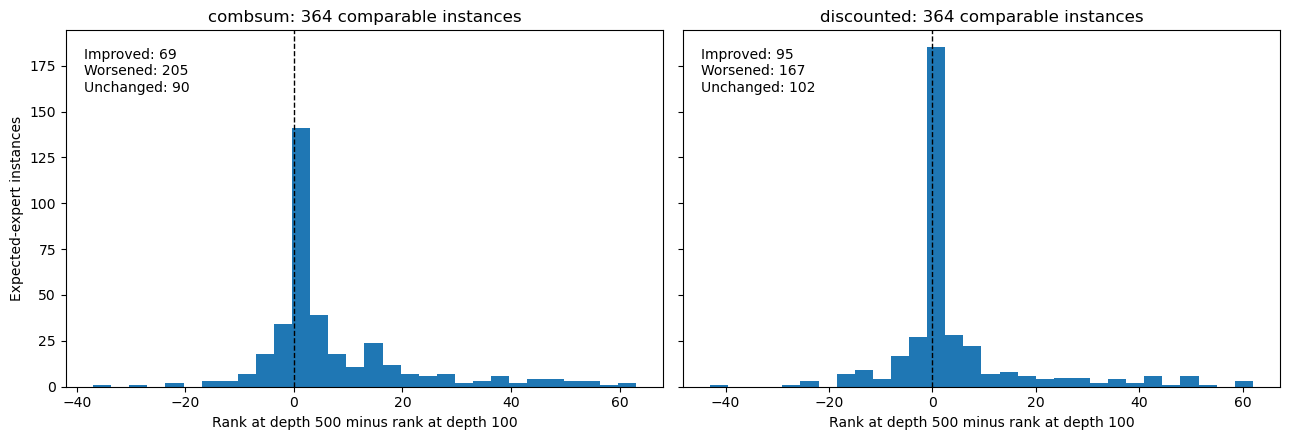

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, method in zip(axes, METHODS):
    a = pd.to_numeric(df[f'rank_{method}_100'], errors='coerce')
    b = pd.to_numeric(df[f'rank_{method}_500'], errors='coerce')
    delta = (b-a).dropna()
    ax.hist(delta, bins=30)
    ax.axvline(0, linestyle='--', color='black', linewidth=1)
    ax.set(title=f'{method}: {len(delta)} comparable instances', xlabel='Rank at depth 500 minus rank at depth 100')
    ax.text(.03, .95, f'Improved: {(delta < 0).sum()}\nWorsened: {(delta > 0).sum()}\nUnchanged: {(delta == 0).sum()}',
            transform=ax.transAxes, va='top')
axes[0].set_ylabel('Expected-expert instances')
fig.tight_layout()
fig.savefig(PLOT_DIR / '04_rank_movement_100_to_500.png', dpi=180)
plt.show()

## 5. Inspect concrete failures

Examples of expected experts with documents retrieved but ranked below 10, or with no documents retrieved at depth 100. Use these to guide manual error analysis.

In [6]:
cols = ['query_id', 'query_type', 'query', 'expected_expert', 'indexed_document_count',
        'expert_document_hits_100', 'rank_discounted_100', 'status_at_100_discounted']
for status in ['ranking_failure', 'no_document_in_top_100']:
    subset = df[df.status_at_100_discounted == status]
    print(f'\n{status}: {len(subset)} instances')
    display(subset[cols].head(12))


ranking_failure: 122 instances


,query_id,query_type,query,expected_expert,indexed_document_count,expert_document_hits_100,rank_discounted_100,status_at_100_discounted
5,3,academic,intelligent building blocks and robotics,Andres Faina,76,2,22.0,ranking_failure
8,4,student_style,Can we build furniture that knows its own shape?,Andres Faina,76,1,32.0,ranking_failure
9,4,student_style,Can we build furniture that knows its own shape?,Rodrigo Moreno Garcia,19,1,31.0,ranking_failure
11,6,student_style,How can chatbots tell us when they are unsure?,Christian Hardmeier,95,1,30.0,ranking_failure
13,8,student_style,How can technology make renewable energy syste...,Yvonne Dittrich,155,1,18.0,ranking_failure
14,9,academic,psychology and human computer interaction design,Elisa Mekler,34,2,13.0,ranking_failure
21,16,student_style,Why do people lose trust in AI systems?,Aske Mottelson,46,1,27.0,ranking_failure
28,23,academic,payment system resilience,Sunniva Sandbukt,26,2,15.0,ranking_failure
37,30,student_style,How can we predict disruptions in shipping net...,Jonas Juul,25,1,29.0,ranking_failure
41,34,student_style,Can we keep our messages private from surveill...,Rosario Giustolisi,33,1,29.0,ranking_failure



no_document_in_top_100: 222 instances


,query_id,query_type,query,expected_expert,indexed_document_count,expert_document_hits_100,rank_discounted_100,status_at_100_discounted
0,1,academic,digital biomarkers for mental health,Stella Grasshof,31,0,NaN,no_document_in_top_100
1,1,academic,digital biomarkers for mental health,Martin Lund Trinhammer,1,0,NaN,no_document_in_top_100
3,2,student_style,Can AI use facial expressions to help understa...,Martin Lund Trinhammer,1,0,NaN,no_document_in_top_100
6,3,academic,intelligent building blocks and robotics,Rodrigo Moreno Garcia,19,0,NaN,no_document_in_top_100
15,10,student_style,How can psychology help us design better apps?,Elisa Mekler,34,0,NaN,no_document_in_top_100
20,15,academic,trust in artificial intelligence,Aske Mottelson,46,0,NaN,no_document_in_top_100
24,19,academic,human AI interaction and system failure,Paolo Burelli,92,0,NaN,no_document_in_top_100
25,20,student_style,How do people respond when automated systems m...,Paolo Burelli,92,0,NaN,no_document_in_top_100
27,22,student_style,What would happen if hackers attacked critical...,Oksana Kulyk,55,0,NaN,no_document_in_top_100
32,27,academic,Theoretical computer and european conference,Thore Husfeldt,55,0,NaN,no_document_in_top_100


### Interpretation — BM25F Failure Analysis

The failure analysis reveals several important limitations of the document-centric expert retrieval approach.

- **Retrieval vs. ranking failures:** At depth 100, a substantial proportion of expected experts have no documents among the retrieved results. However, others have matching documents but still fail to reach the top 10, indicating that both document retrieval and score aggregation contribute to missed experts.
- **Query type differences:** Academic queries achieve higher top-10 coverage than student-style queries. Student-style queries have more retrieval failures, suggesting that vocabulary mismatch between natural-language questions and academic documents is an important limitation of lexical retrieval.
- **Increasing retrieval depth does not improve ranking:** For Discounted CombSUM, top-10 coverage decreases from 41.3% at depth 100 to 38.6% at depth 250 and 39.6% at depth 500. Standard CombSUM declines from 38.2% to 32.4%.
- **More documents introduce ranking competition:** As retrieval depth increases, retrieval failures decrease while ranking failures increase. Additional documents allow more researchers to accumulate relevance scores, potentially pushing previously highly ranked expected experts below the top 10.
- **Discounting improves robustness:** Between depths 100 and 500, standard CombSUM worsens the ranks of 205 expected-expert instances and improves 69, compared with 167 worsened and 95 improved under Discounted CombSUM (among 364 comparable instances per method). This suggests that discounting partially mitigates the negative effects of accumulating additional evidence.

**Conclusion:** Simply retrieving more BM25F documents is insufficient to improve expert search performance. The results suggest that unrestricted score accumulation can introduce ranking bias as retrieval depth increases. Discounted CombSUM partially addresses this problem but does not eliminate it.

**Implications for further development:** Future improvements should investigate both semantic document retrieval, to address vocabulary mismatch and missing evidence, and more robust researcher-level aggregation, to prevent researchers with many moderately relevant documents from dominating the ranking.

**Methodological limitation:** These conclusions are based on incomplete known-positive relevance judgments. Additionally, rank-movement comparisons only include expected experts with ranks available at both depths.